saved beta_scan_steps.png


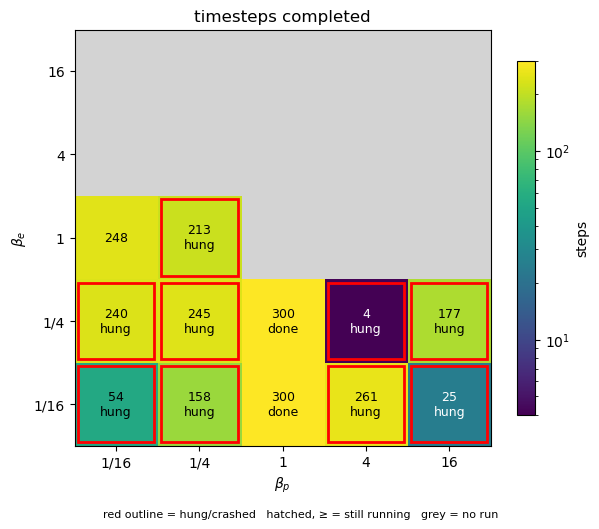

In [4]:
# shared code and paths (see README.md and shared/)
import sys
from pathlib import Path
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "shared" / "paths.py").exists())
sys.path.insert(0, str(REPO))
from shared.paths import DATA_ROOT, NAS_ROOT, results_dir, cache_dir as shared_cache_dir
RESULTS = results_dir("quality_checks", "SimulationHeatMap")
"""
Heatmap of the number of timesteps each run completed across the (beta_p, beta_e) scan.

Fill in the two tables below: rows are beta_p, columns are beta_e, both 1/16 ... 16.
The plot is transposed: beta_p runs along the x-axis and beta_e up the y-axis.
STEPS: the last iteration number in the run's log (None = no run).
STATUS: "H" hung   "C" crashed   "R" still running   "D" finished   "" no run
Running jobs are lower bounds (hatched, marked >=); hung/crashed runs get a red outline.
"""
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, Normalize
from matplotlib.patches import Rectangle

LABELS = ["1/16", "1/4", "1", "4", "16"]

#           bp=1/16  bp=1/4  bp=1    bp=4    bp=16
STEPS = [
    [54,    240,   248,   None,   None],     # be = 1/16
    [158,    245,   213,   None,   None],     # be = 1/4
    [300,    300,   None,   None,   None],     # be = 1
    [261,    4,   None,   None,   None],     # be = 4
    [25,    177,   None,   None,   None],     # be = 16
]

STATUS = [
    ["H",      "H",     "",     "",     ""],       # be = 1/16
    ["H",      "H",     "H",     "",     ""],       # be = 1/4
    ["D",      "D",     "",     "",     ""],       # be = 1
    ["H",      "H",     "",     "",     ""],       # be = 4
    ["H",      "H",     "",     "",     ""],       # be = 16
]

LOG_COLOUR = True
OUTFILE = str(RESULTS / "beta_scan_steps.png")
NAMES = {"H": "hung", "C": "crashed", "R": "running", "D": "done"}

data = np.array([[np.nan if v is None else float(v) for v in row] for row in STEPS])
finite = data[np.isfinite(data)]
if finite.size == 0:
    print("STEPS is empty: fill in the tables at the top of the script.")
lo, hi = (finite.min(), finite.max()) if finite.size else (0.0, 1.0)
norm = LogNorm(lo, hi) if LOG_COLOUR and lo > 0 and hi > lo else Normalize(lo, max(hi, lo + 1))
cmap = plt.get_cmap("viridis").copy()
cmap.set_bad("lightgrey")

fig, ax = plt.subplots(figsize=(6.2, 5.2))
im = ax.imshow(np.ma.masked_invalid(data.T), origin="lower", cmap=cmap, norm=norm)
for i in range(5):
    for j in range(5):
        s, v = STATUS[i][j], data[i, j]
        if np.isnan(v) and not s:
            continue
        value = "–" if np.isnan(v) else f"{v:.0f}"
        if s == "R" and np.isfinite(v):
            value = "≥" + value
        dark = np.isfinite(v) and float(norm(v)) < 0.55
        ax.text(i, j, value + (f"\n{NAMES.get(s, s)}" if s else ""), ha="center", va="center",
                fontsize=9, color="white" if dark else "black")
        if s == "R":
            ax.add_patch(Rectangle((i - 0.5, j - 0.5), 1, 1, fill=False, hatch="//",
                                   edgecolor="white", lw=0))
        if s in ("H", "C"):
            ax.add_patch(Rectangle((i - 0.46, j - 0.46), 0.92, 0.92, fill=False,
                                   edgecolor="red", lw=2))

ax.set_xticks(range(5), LABELS)
ax.set_yticks(range(5), LABELS)
ax.set_xlabel(r"$\beta_p$")
ax.set_ylabel(r"$\beta_e$")
ax.set_title("timesteps completed")
fig.colorbar(im, ax=ax, label="steps", shrink=0.85)
fig.text(0.5, 0.01, "red outline = hung/crashed   hatched, ≥ = still running   grey = no run",
         ha="center", fontsize=8)
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(OUTFILE, dpi=150)
print(f"saved {OUTFILE}")